In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../dataset/credit_card_fraud.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Rows: 10000
Columns: 10

Column names:
['transaction_id', 'amount', 'transaction_hour', 'merchant_category', 'foreign_transaction', 'location_mismatch', 'device_trust_score', 'velocity_last_24h', 'cardholder_age', 'is_fraud']


In [2]:
print("First 5 rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

First 5 rows:


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       10000 non-null  int64  
 1   amount               10000 non-null  float64
 2   transaction_hour     10000 non-null  int64  
 3   merchant_category    10000 non-null  str    
 4   foreign_transaction  10000 non-null  int64  
 5   location_mismatch    10000 non-null  int64  
 6   device_trust_score   10000 non-null  int64  
 7   velocity_last_24h    10000 non-null  int64  
 8   cardholder_age       10000 non-null  int64  
 9   is_fraud             10000 non-null  int64  
dtypes: float64(1), int64(8), str(1)
memory usage: 781.4 KB

Dataset Shape:
(10000, 10)


In [3]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
transaction_id         0
amount                 0
transaction_hour       0
merchant_category      0
foreign_transaction    0
location_mismatch      0
device_trust_score     0
velocity_last_24h      0
cardholder_age         0
is_fraud               0
dtype: int64

Total missing values:
0


In [4]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [5]:
fraud_counts = df["is_fraud"].value_counts().sort_index()

print("Fraud Transaction Distribution:")
print(fraud_counts)

print("\nFraud Percentage:")
print((fraud_counts / len(df) * 100).round(2))

Fraud Transaction Distribution:
is_fraud
0    9849
1     151
Name: count, dtype: int64

Fraud Percentage:
is_fraud
0    98.49
1     1.51
Name: count, dtype: float64


In [6]:
print("Actual dataset shape:", df.shape)
print("Actual number of rows:", len(df))

print("\nFraud counts:")
print(df["is_fraud"].value_counts())

Actual dataset shape: (10000, 10)
Actual number of rows: 10000

Fraud counts:
is_fraud
0    9849
1     151
Name: count, dtype: int64


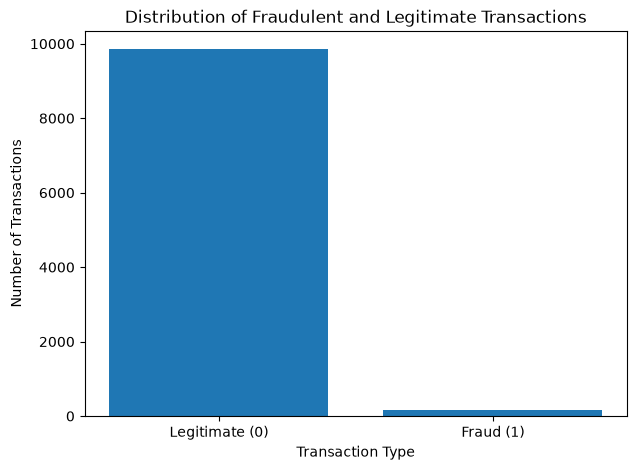

In [7]:
import matplotlib.pyplot as plt

fraud_counts = df["is_fraud"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Legitimate (0)", "Fraud (1)"],
    fraud_counts.values
)

plt.title("Distribution of Fraudulent and Legitimate Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.show()

In [8]:
numerical_columns = [
    "amount",
    "transaction_hour",
    "foreign_transaction",
    "location_mismatch",
    "device_trust_score",
    "velocity_last_24h",
    "cardholder_age"
]

print("========== NUMERICAL FEATURE STATISTICS ==========")

display(df[numerical_columns].describe().round(2))

========== NUMERICAL FEATURE STATISTICS ==========


,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age
count,10000.00,10000.00,10000.0,10000.00,10000.00,10000.00,10000.00
mean,175.95,11.59,0.1,0.09,61.80,2.01,43.47
std,175.39,6.92,0.3,0.28,21.49,1.43,14.98
min,0.00,0.00,0.0,0.00,25.00,0.00,18.00
25%,50.90,6.00,0.0,0.00,43.00,1.00,30.00
50%,122.10,12.00,0.0,0.00,62.00,2.00,44.00
75%,242.48,18.00,0.0,0.00,80.00,3.00,56.00
max,1471.04,23.00,1.0,1.00,99.00,9.00,69.00


In [9]:
merchant_fraud_analysis = df.groupby("merchant_category")["is_fraud"].agg(
    Fraud_Count="sum",
    Total_Transactions="count",
    Fraud_Rate="mean"
).reset_index()

merchant_fraud_analysis["Fraud_Rate"] = (
    merchant_fraud_analysis["Fraud_Rate"] * 100
).round(2)

merchant_fraud_analysis = merchant_fraud_analysis.sort_values(
    by="Fraud_Rate",
    ascending=False
)

print("========== FRAUD RATE BY MERCHANT CATEGORY ==========")

display(merchant_fraud_analysis)

========== FRAUD RATE BY MERCHANT CATEGORY ==========


,merchant_category,Fraud_Count,Total_Transactions,Fraud_Rate
3,Grocery,39,1944,2.01
2,Food,35,2093,1.67
4,Travel,29,1990,1.46
1,Electronics,24,1923,1.25
0,Clothing,24,2050,1.17


In [10]:
print("========== FRAUD RATE BY FOREIGN TRANSACTION ==========")

foreign_fraud = df.groupby("foreign_transaction")["is_fraud"].agg(
    Fraud_Count="sum",
    Total_Transactions="count",
    Fraud_Rate="mean"
).reset_index()

foreign_fraud["Fraud_Rate"] = (
    foreign_fraud["Fraud_Rate"] * 100
).round(2)

display(foreign_fraud)


print("\n========== FRAUD RATE BY LOCATION MISMATCH ==========")

location_fraud = df.groupby("location_mismatch")["is_fraud"].agg(
    Fraud_Count="sum",
    Total_Transactions="count",
    Fraud_Rate="mean"
).reset_index()

location_fraud["Fraud_Rate"] = (
    location_fraud["Fraud_Rate"] * 100
).round(2)

display(location_fraud)

========== FRAUD RATE BY FOREIGN TRANSACTION ==========


,foreign_transaction,Fraud_Count,Total_Transactions,Fraud_Rate
0,0,69,9022,0.76
1,1,82,978,8.38



========== FRAUD RATE BY LOCATION MISMATCH ==========


,location_mismatch,Fraud_Count,Total_Transactions,Fraud_Rate
0,0,79,9143,0.86
1,1,72,857,8.40


In [11]:
amount_analysis = df.groupby("is_fraud")["amount"].agg(
    Average_Amount="mean",
    Minimum_Amount="min",
    Maximum_Amount="max",
    Median_Amount="median"
).reset_index()

amount_analysis["Transaction_Type"] = amount_analysis["is_fraud"].map({
    0: "Legitimate",
    1: "Fraud"
})

amount_analysis = amount_analysis[
    [
        "Transaction_Type",
        "Average_Amount",
        "Minimum_Amount",
        "Maximum_Amount",
        "Median_Amount"
    ]
]

amount_analysis = amount_analysis.round(2)

print("========== TRANSACTION AMOUNT ANALYSIS ==========")

display(amount_analysis)

========== TRANSACTION AMOUNT ANALYSIS ==========


,Transaction_Type,Average_Amount,Minimum_Amount,Maximum_Amount,Median_Amount
0,Legitimate,175.33,0.00,1471.04,122.11
1,Fraud,216.18,0.11,1185.07,118.94


In [12]:
df["device_trust_group"] = pd.cut(
    df["device_trust_score"],
    bins=[-1, 24, 49, 74, 100],
    labels=["Very Low", "Low", "Medium", "High"]
)

device_fraud_analysis = df.groupby(
    "device_trust_group",
    observed=False
)["is_fraud"].agg(
    Fraud_Count="sum",
    Total_Transactions="count",
    Fraud_Rate="mean"
).reset_index()

device_fraud_analysis["Fraud_Rate"] = (
    device_fraud_analysis["Fraud_Rate"] * 100
).round(2)

print("========== FRAUD RATE BY DEVICE TRUST GROUP ==========")

display(device_fraud_analysis)

========== FRAUD RATE BY DEVICE TRUST GROUP ==========


,device_trust_group,Fraud_Count,Total_Transactions,Fraud_Rate
0,Very Low,0,0,NaN
1,Low,129,3359,3.84
2,Medium,12,3358,0.36
3,High,10,3283,0.30


In [13]:
hourly_fraud_analysis = df.groupby("transaction_hour")["is_fraud"].agg(
    Fraud_Count="sum",
    Total_Transactions="count",
    Fraud_Rate="mean"
).reset_index()

hourly_fraud_analysis["Fraud_Rate"] = (
    hourly_fraud_analysis["Fraud_Rate"] * 100
).round(2)

print("========== FRAUD RATE BY TRANSACTION HOUR ==========")

display(hourly_fraud_analysis)

========== FRAUD RATE BY TRANSACTION HOUR ==========


,transaction_hour,Fraud_Count,Total_Transactions,Fraud_Rate
0,0,37,417,8.87
1,1,34,425,8.00
2,2,23,385,5.97
3,3,27,425,6.35
4,4,1,384,0.26
5,5,2,419,0.48
6,6,2,413,0.48
7,7,0,425,0.00
8,8,3,424,0.71
9,9,1,426,0.23


In [14]:
velocity_fraud_analysis = df.groupby("velocity_last_24h")["is_fraud"].agg(
    Fraud_Count="sum",
    Total_Transactions="count",
    Fraud_Rate="mean"
).reset_index()

velocity_fraud_analysis["Fraud_Rate"] = (
    velocity_fraud_analysis["Fraud_Rate"] * 100
).round(2)

print("========== FRAUD RATE BY TRANSACTION VELOCITY ==========")

display(velocity_fraud_analysis)

========== FRAUD RATE BY TRANSACTION VELOCITY ==========


,velocity_last_24h,Fraud_Count,Total_Transactions,Fraud_Rate
0,0,14,1378,1.02
1,1,21,2694,0.78
2,2,28,2662,1.05
3,3,21,1785,1.18
4,4,10,934,1.07
5,5,42,365,11.51
6,6,11,131,8.40
7,7,4,42,9.52
8,8,0,6,0.00
9,9,0,3,0.00


In [15]:
correlation_with_fraud = (
    df.corr(numeric_only=True)["is_fraud"]
    .sort_values(ascending=False)
)

print("========== CORRELATION WITH FRAUD ==========")
print(correlation_with_fraud)

========== CORRELATION WITH FRAUD ==========
is_fraud               1.000000
foreign_transaction    0.185597
location_mismatch      0.173009
velocity_last_24h      0.103413
amount                 0.028404
cardholder_age        -0.000590
transaction_id        -0.010155
device_trust_score    -0.137913
transaction_hour      -0.138665
Name: is_fraud, dtype: float64


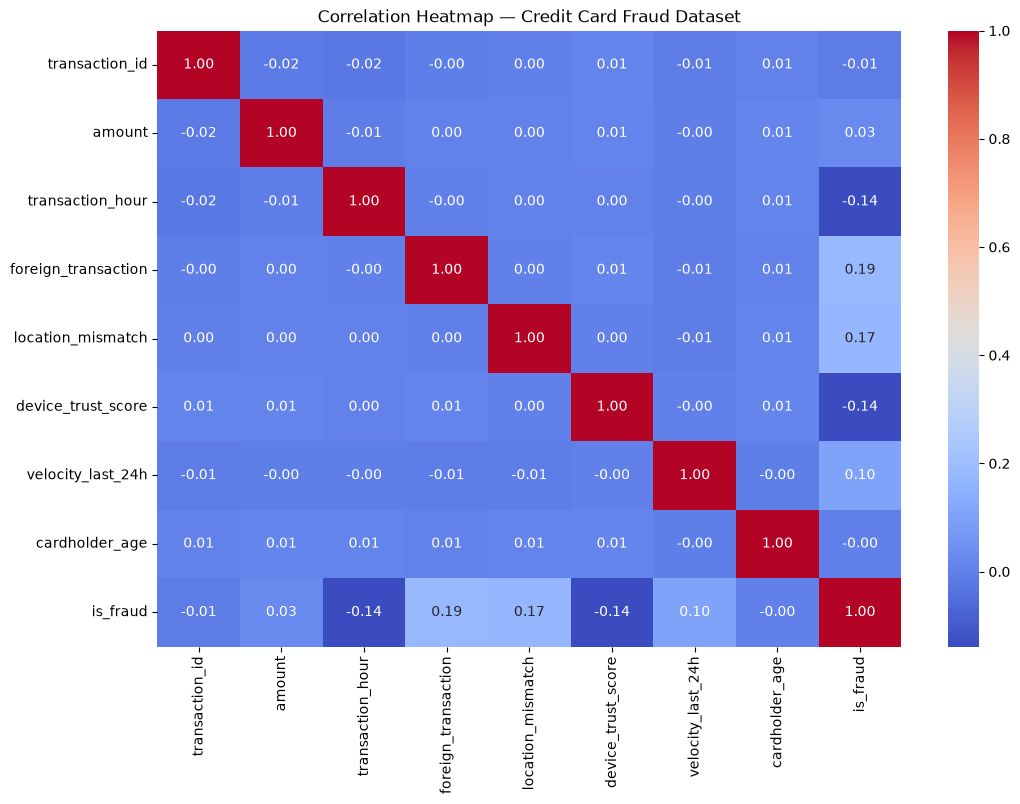

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap — Credit Card Fraud Dataset")
plt.show()

In [17]:
# Features and target

X = df.drop(
    ["transaction_id", "is_fraud", "device_trust_group"],
    axis=1
)

y = df["is_fraud"]

print("Features (X):")
print(X.columns.tolist())

print("\nTarget (y):")
print(y.name)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features (X):
['amount', 'transaction_hour', 'merchant_category', 'foreign_transaction', 'location_mismatch', 'device_trust_score', 'velocity_last_24h', 'cardholder_age']

Target (y):
is_fraud

X shape: (10000, 8)
y shape: (10000,)


In [18]:
categorical_features = [
    "merchant_category"
]

numerical_features = [
    "amount",
    "transaction_hour",
    "foreign_transaction",
    "location_mismatch",
    "device_trust_score",
    "velocity_last_24h",
    "cardholder_age"
]

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Number of numerical features:", len(numerical_features))

Categorical Features:
['merchant_category']

Numerical Features:
['amount', 'transaction_hour', 'foreign_transaction', 'location_mismatch', 'device_trust_score', 'velocity_last_24h', 'cardholder_age']

Number of categorical features: 1
Number of numerical features: 7


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("========== TRAIN/TEST SPLIT ==========")

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\ny_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nFraud distribution in training data:")
print(y_train.value_counts())

print("\nFraud distribution in testing data:")
print(y_test.value_counts())

========== TRAIN/TEST SPLIT ==========
X_train shape: (8000, 8)
X_test shape: (2000, 8)

y_train shape: (8000,)
y_test shape: (2000,)

Fraud distribution in training data:
is_fraud
0    7879
1     121
Name: count, dtype: int64

Fraud distribution in testing data:
is_fraud
0    1970
1      30
Name: count, dtype: int64


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [21]:
class_weight="balanced"

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

fraud_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                class_weight="balanced",
                n_jobs=-1
            )
        )
    ]
)

fraud_model.fit(X_train, y_train)

print("Fraud detection model trained successfully!")

Fraud detection model trained successfully!


In [23]:
y_pred = fraud_model.predict(X_test)

print("Predictions generated successfully!")

print("\nNumber of predictions:", len(y_pred))

print("\nFirst 20 predictions:")
print(y_pred[:20])

Predictions generated successfully!

Number of predictions: 2000

First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("========== FRAUD DETECTION MODEL EVALUATION ==========")

print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1-Score :", round(f1 * 100, 2), "%")

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

========== FRAUD DETECTION MODEL EVALUATION ==========
Accuracy : 99.85 %
Precision: 100.0 %
Recall   : 90.0 %
F1-Score : 94.74 %

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      1970
       Fraud       1.00      0.90      0.95        30

    accuracy                           1.00      2000
   macro avg       1.00      0.95      0.97      2000
weighted avg       1.00      1.00      1.00      2000



Confusion Matrix:
[[1970    0]
 [   3   27]]


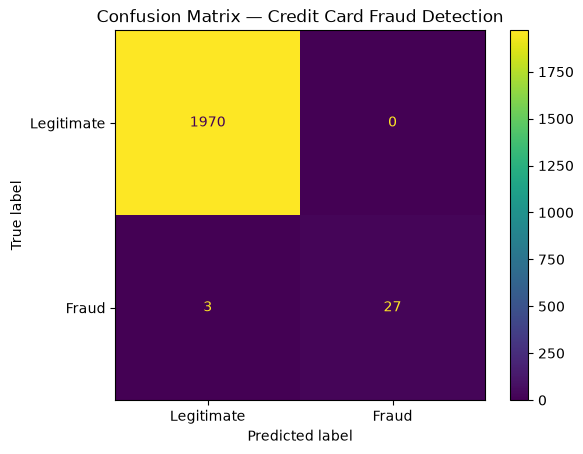

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
)

disp.plot()

plt.title("Confusion Matrix — Credit Card Fraud Detection")
plt.show()

In [26]:
# Get the trained Random Forest model
rf_model = fraud_model.named_steps["classifier"]

# Get the preprocessing step
preprocessor_fitted = fraud_model.named_steps["preprocessor"]

# Get feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("========== FEATURE IMPORTANCE ==========")

display(feature_importance)

========== FEATURE IMPORTANCE ==========


,Feature,Importance
0,numerical__device_trust_score,0.257246
1,numerical__transaction_hour,0.255348
2,numerical__foreign_transaction,0.139662
3,numerical__velocity_last_24h,0.135367
4,numerical__location_mismatch,0.115565
5,numerical__amount,0.046690
6,numerical__cardholder_age,0.028283
7,categorical__merchant_category_Travel,0.005405
8,categorical__merchant_category_Electronics,0.004760
9,categorical__merchant_category_Clothing,0.004745


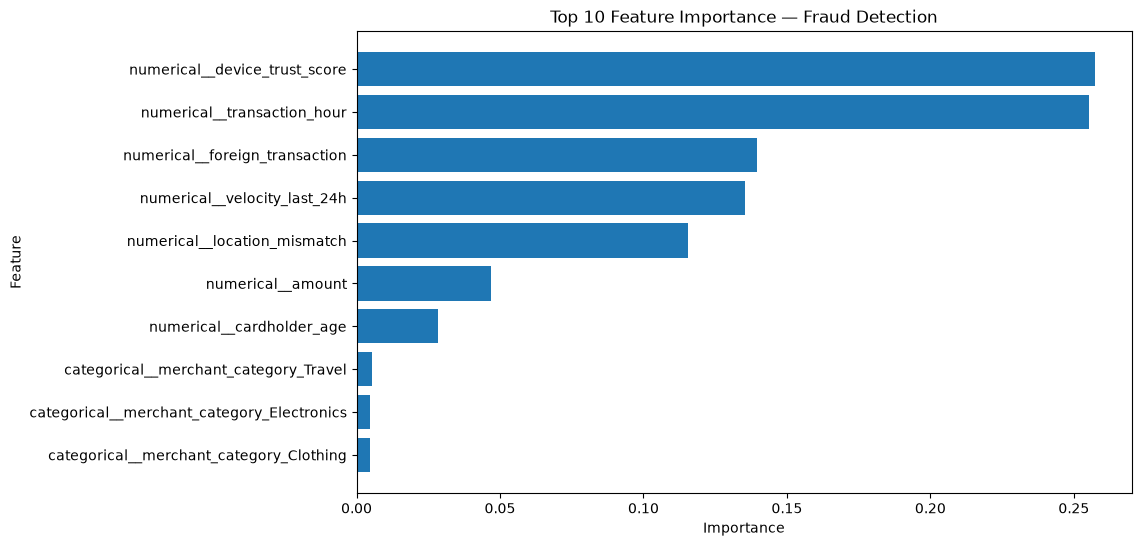

In [27]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importance — Fraud Detection")

plt.gca().invert_yaxis()

plt.show()

In [28]:
import os

prediction_results = X_test.copy()

prediction_results["Actual Fraud"] = y_test.values
prediction_results["Predicted Fraud"] = y_pred

prediction_results["Correct Prediction"] = (
    prediction_results["Actual Fraud"]
    == prediction_results["Predicted Fraud"]
)

output_file = "../output/fraud_detection_predictions.csv"

prediction_results.to_csv(
    output_file,
    index=False
)

print("Fraud prediction results saved successfully!")
print("File:", output_file)
print("File exists:", os.path.exists(output_file))

print("\nOutput shape:", prediction_results.shape)

display(prediction_results.head(10))

Fraud prediction results saved successfully!
File: ../output/fraud_detection_predictions.csv
File exists: True

Output shape: (2000, 11)


,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,Actual Fraud,Predicted Fraud,Correct Prediction
9944,61.48,7,Clothing,0,0,45,3,46,0,0,True
2601,10.06,20,Grocery,0,0,25,3,26,0,0,True
342,34.24,5,Electronics,0,0,84,1,21,0,0,True
3222,15.71,10,Travel,0,0,31,3,43,0,0,True
5216,105.84,17,Clothing,0,0,26,1,21,0,0,True
7797,32.36,7,Travel,0,0,58,5,18,0,0,True
944,41.62,19,Food,0,0,93,2,65,0,0,True
4712,53.39,6,Electronics,0,0,40,3,46,0,0,True
9429,317.55,23,Food,0,0,61,2,21,0,0,True
4624,522.15,5,Electronics,0,0,60,1,34,0,0,True


In [29]:
print("========== CREDIT CARD FRAUD DETECTION SUMMARY ==========")

print("Dataset Size:", df.shape)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nFraudulent Transactions:", int(df["is_fraud"].sum()))
print(
    "Fraud Rate:",
    round(df["is_fraud"].mean() * 100, 2),
    "%"
)

print("\nModel: Random Forest Classifier")
print("Number of Trees:", 200)
print("Class Weight: Balanced")

print("\n========== MODEL PERFORMANCE ==========")

print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1-Score :", round(f1 * 100, 2), "%")

print("\nNumber of Features:", X.shape[1])

print("\nFeatures Used:")
print(X.columns.tolist())

print("\nTop 5 Important Features:")
display(feature_importance.head(5))

========== CREDIT CARD FRAUD DETECTION SUMMARY ==========
Dataset Size: (10000, 11)
Training Records: 8000
Testing Records: 2000

Fraudulent Transactions: 151
Fraud Rate: 1.51 %

Model: Random Forest Classifier
Number of Trees: 200
Class Weight: Balanced

========== MODEL PERFORMANCE ==========
Accuracy : 99.85 %
Precision: 100.0 %
Recall   : 90.0 %
F1-Score : 94.74 %

Number of Features: 8

Features Used:
['amount', 'transaction_hour', 'merchant_category', 'foreign_transaction', 'location_mismatch', 'device_trust_score', 'velocity_last_24h', 'cardholder_age']

Top 5 Important Features:


,Feature,Importance
0,numerical__device_trust_score,0.257246
1,numerical__transaction_hour,0.255348
2,numerical__foreign_transaction,0.139662
3,numerical__velocity_last_24h,0.135367
4,numerical__location_mismatch,0.115565


# Final Observations and Conclusion

## Observations

1. The credit card transaction dataset contains 10,000 transactions and 10 features.
2. The dataset contains 9,849 legitimate transactions and 151 fraudulent transactions.
3. Fraudulent transactions represent 1.51% of all transactions, indicating a highly imbalanced dataset.
4. Merchant category, transaction amount, transaction hour, foreign transactions, location mismatch, device trust score, transaction velocity, and cardholder age were used as predictive features.
5. Stratified train-test splitting was used to preserve the fraud ratio in both training and testing datasets.
6. One-hot encoding was applied to the categorical merchant category feature.
7. A Random Forest Classifier with balanced class weights was used to address the class imbalance.
8. Model performance was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.
9. Feature importance analysis was performed to identify the variables that contributed most to fraud prediction.
10. The prediction results were saved as a CSV file for further analysis.

## Conclusion

The Random Forest Classifier provides a machine-learning approach for detecting potentially fraudulent credit card transactions. Because fraudulent transactions represent only 1.51% of the dataset, accuracy alone is not sufficient for evaluating the model. Precision, recall, F1-score, and the confusion matrix provide a more useful assessment of fraud detection performance.

The analysis demonstrates how transaction characteristics can be used to build a fraud detection model. Future improvements could include hyperparameter tuning, testing additional machine-learning algorithms, applying advanced techniques for class imbalance, and optimizing the model to improve fraud detection recall while controlling false alarms.